In [1]:
from sklearn.datasets import fetch_20newsgroups

# Load the training corpus
news = fetch_20newsgroups(
    subset="train",
    remove=("headers", "footers", "quotes")
)

docs = news.data

print("Total documents:", len(docs))
print("Total categories:", len(news.target_names))
print("\nFirst 500 characters of document 1:")
print(docs[0][:500])

Total documents: 11314
Total categories: 20

First 500 characters of document 1:
I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I know. If anyone can tellme a model name, engine specs, years
of production, where this car is made, history, or whatever info you
have on this funky looking car, please e-mail.


In [2]:
import pandas as pd

# Count documents in each newsgroup category
category_counts = pd.Series(
    news.target
).value_counts().sort_index()

category_df = pd.DataFrame({
    "Category": news.target_names,
    "Documents": category_counts.values
})

display(category_df)

,Category,Documents
0,alt.atheism,480
1,comp.graphics,584
2,comp.os.ms-windows.misc,591
3,comp.sys.ibm.pc.hardware,590
4,comp.sys.mac.hardware,578
5,comp.windows.x,593
6,misc.forsale,585
7,rec.autos,594
8,rec.motorcycles,598
9,rec.sport.baseball,597


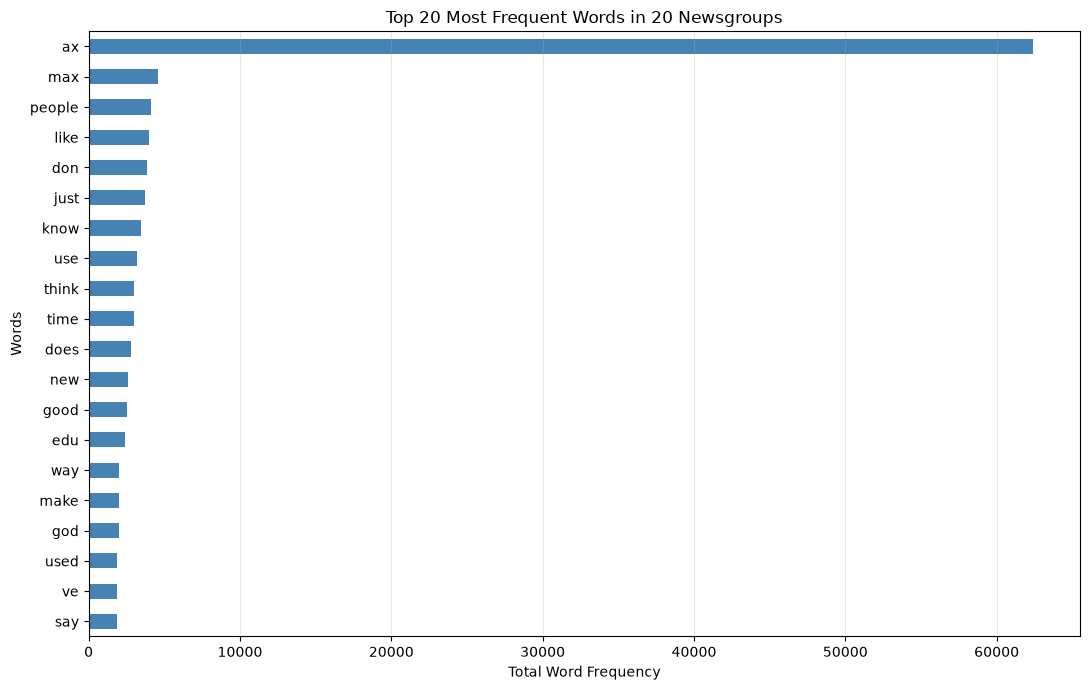

In [3]:
from sklearn.feature_extraction.text import CountVectorizer
import matplotlib.pyplot as plt

# Convert text into word counts
vectorizer = CountVectorizer(
    stop_words="english",
    max_features=20
)

word_matrix = vectorizer.fit_transform(docs)

# Calculate total frequency of each word
word_counts = pd.Series(
    word_matrix.sum(axis=0).A1,
    index=vectorizer.get_feature_names_out()
).sort_values()

# Create an honest frequency visualization
plt.figure(figsize=(11, 7))

word_counts.plot(
    kind="barh",
    color="steelblue"
)

plt.title("Top 20 Most Frequent Words in 20 Newsgroups")
plt.xlabel("Total Word Frequency")
plt.ylabel("Words")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

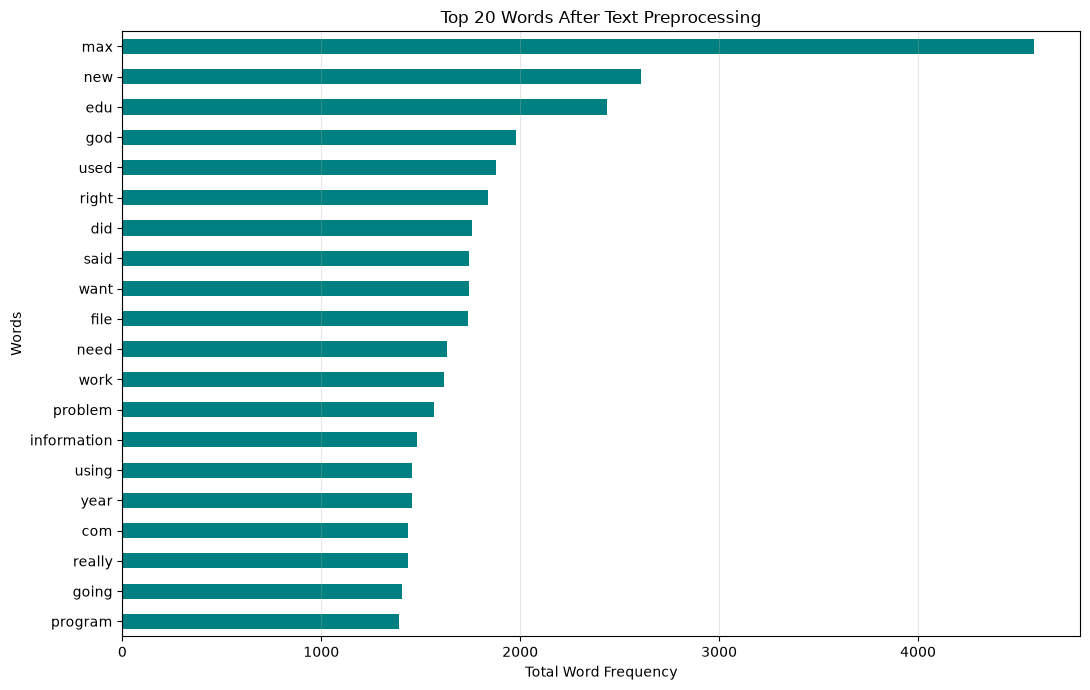

In [5]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction import text
import matplotlib.pyplot as plt
import pandas as pd

# Additional corpus-specific and conversational stop words
extra_stopwords = {
    "ax", "don", "ve", "does", "just", "like",
    "know", "think", "people", "use", "good",
    "make", "say", "way", "time"
}

all_stopwords = list(
    text.ENGLISH_STOP_WORDS.union(extra_stopwords)
)

clean_vectorizer = CountVectorizer(
    stop_words=all_stopwords,
    max_features=20,
    token_pattern=r"(?u)\b[a-zA-Z]{3,}\b"
)

clean_matrix = clean_vectorizer.fit_transform(docs)

clean_counts = pd.Series(
    clean_matrix.sum(axis=0).A1,
    index=clean_vectorizer.get_feature_names_out()
).sort_values()

plt.figure(figsize=(11, 7))
clean_counts.plot(kind="barh", color="teal")

plt.title("Top 20 Words After Text Preprocessing")
plt.xlabel("Total Word Frequency")
plt.ylabel("Words")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

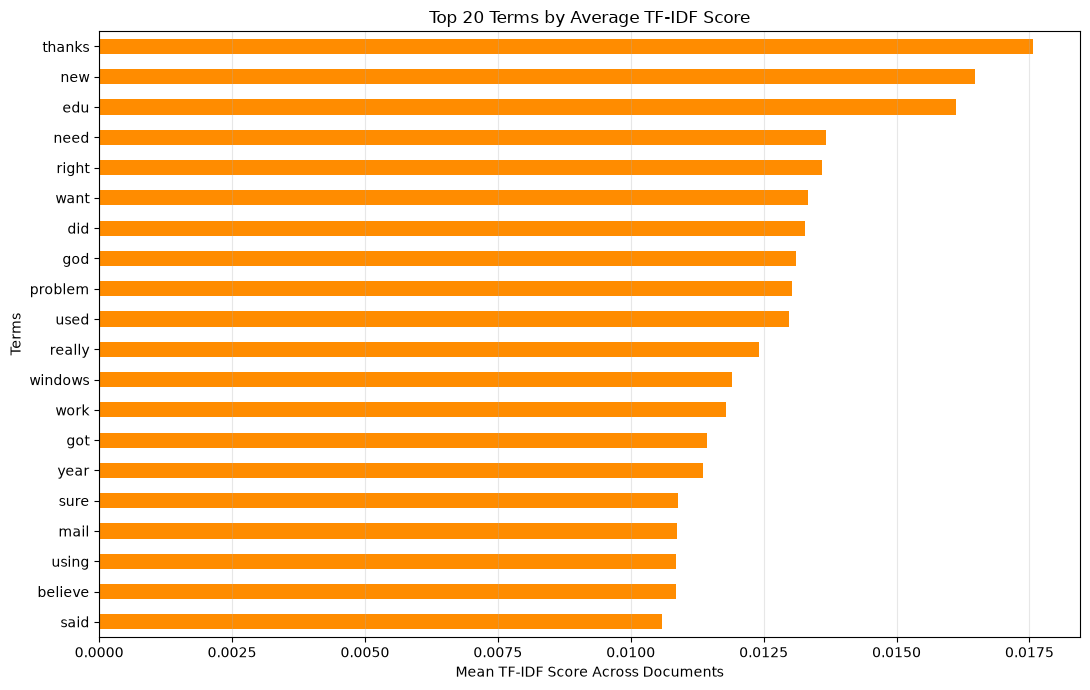

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd
import matplotlib.pyplot as plt

# Use the same preprocessing as our cleaned frequency chart
tfidf_vectorizer = TfidfVectorizer(
    stop_words=all_stopwords,
    max_features=1000,
    token_pattern=r"(?u)\b[a-zA-Z]{3,}\b"
)

tfidf_matrix = tfidf_vectorizer.fit_transform(docs)

# Average TF-IDF score across all documents
tfidf_scores = pd.Series(
    tfidf_matrix.mean(axis=0).A1,
    index=tfidf_vectorizer.get_feature_names_out()
)

top_tfidf = tfidf_scores.nlargest(20).sort_values()

plt.figure(figsize=(11, 7))
top_tfidf.plot(kind="barh", color="darkorange")

plt.title("Top 20 Terms by Average TF-IDF Score")
plt.xlabel("Mean TF-IDF Score Across Documents")
plt.ylabel("Terms")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
from bertopic import BERTopic

# Select 300 non-empty documents
sample_docs = [doc for doc in docs if doc.strip()][:300]

# Initialize BERTopic
topic_model = BERTopic(
    language="english",
    min_topic_size=10,
    verbose=True
)

# Discover topics
topics, probs = topic_model.fit_transform(sample_docs)

# Display discovered topics
topic_info = topic_model.get_topic_info()

display(topic_info)

c:\Users\SIMBAH\Desktop\Visualisation\DATVIS6401\dats6401\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-10-17 23:35:01,853 - BERTopic - Embedding - Transforming documents to embeddings.
Batches: 100%|██████████| 10/10 [00:06<00:00,  1.58it/s]
2026-10-17 23:35:14,925 - BERTopic - Embedding - Completed ✓
2026-10-17 23:35:14,925 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-17 23:35:26,882 - BERTopic - Dimensionality - Completed ✓
2026-10-17 23:35:26,884 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-17 23:35:26,915 - BERTopic - Cluster - Completed ✓
2026-10-17 23:35:26,925 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-17 23:35:27,014 - BERTopic - Representation - Completed ✓


,Topic,Count,Name,Representation,Representative_Docs
0,-1,46,-1_maxaxaxaxaxaxaxaxaxaxaxaxaxaxax_the_to_and,"[maxaxaxaxaxaxaxaxaxaxaxaxaxaxax, the, to, and...","[\nI agree with this assessment. Furthermore,..."
1,0,119,0_the_to_and_of,"[the, to, and, of, for, is, it, in, with, have]","[well folks, my mac plus finally gave up the g..."
2,1,44,1_the_to_and_of,"[the, to, and, of, that, it, you, is, in, on]",[an excellent automatic can be found in the su...
3,2,35,2_the_was_in_0333,"[the, was, in, 0333, to, he, is, and, on, at]","[ \n\n\n\nTed, you're missing a vital point. ..."
4,3,21,3_the_of_that_is,"[the, of, that, is, to, in, not, and, it, as]","[Hello src readers,\n\nAgain the misconception..."
5,4,18,4_the_of_and_in,"[the, of, and, in, to, by, armenian, were, tha...","[\nYes, this is also my understanding of the m..."
6,5,17,5_the_of_is_to,"[the, of, is, to, in, it, and, group, treatmen...",[\n Newsgroups: sci.med\n Path: news.larc....


In [8]:
from sklearn.feature_extraction.text import CountVectorizer

# Remove common English words and corpus-specific artifacts
topic_vectorizer = CountVectorizer(
    stop_words="english",
    token_pattern=r"(?u)\b[a-zA-Z]{3,}\b",
    max_df=0.85,
    min_df=2
)

# Update topic words without retraining embeddings
topic_model.update_topics(
    sample_docs,
    topics=topics,
    vectorizer_model=topic_vectorizer
)

# Display improved topic descriptions
improved_topics = topic_model.get_topic_info()

display(
    improved_topics[["Topic", "Count", "Name", "Representation"]]
)

2026-10-17 23:38:12,382 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


,Topic,Count,Name,Representation
0,-1,46,-1_shuttle_reserve_roll_option,"[shuttle, reserve, roll, option, phone, key, s..."
1,0,119,0_data_program_need_thanks,"[data, program, need, thanks, card, using, tow..."
2,1,44,1_car_gun_rate_turn,"[car, gun, rate, turn, state, miles, weapons, ..."
3,2,35,2_game_teams_tickets_object,"[game, teams, tickets, object, win, doesnt, or..."
4,3,21,3_god_church_did_comes,"[god, church, did, comes, faith, john, beliefs..."
5,4,18,4_war_army_jews_killed,"[war, army, jews, killed, israel, land, world,..."
6,5,17,5_treatment_test_patients_medical,"[treatment, test, patients, medical, disease, ..."


In [11]:
# Visualize the discovered topics
fig = topic_model.visualize_barchart(
    top_n_topics=6,
    n_words=8,
    title="20 Newsgroups — BERTopic Topic Representations"
)
fig.write_html("week7_topics.html", auto_open=True)

In [12]:
import json
from pathlib import Path

# Save topic information for the Streamlit application
topic_records = []

for topic_id in sorted(set(topics)):
    if topic_id == -1:
        continue

    topic_words = topic_model.get_topic(topic_id)

    topic_records.append({
        "topic_id": int(topic_id),
        "count": int(topics.count(topic_id)),
        "words": [
            {"word": word, "score": float(score)}
            for word, score in topic_words[:10]
        ]
    })

# Save alongside the notebook
output_path = Path("week7_topics.json")

with open(output_path, "w", encoding="utf-8") as f:
    json.dump(topic_records, f, indent=2)

print("Saved:", output_path.resolve())
print("Topics exported:", len(topic_records))

Saved: C:\Users\SIMBAH\Desktop\Visualisation\DATVIS6401\DATVIS6401_Week7\week7_topics.json
Topics exported: 6


In [13]:
import numpy as np
import umap

# Reuse the documents and topic assignments from our trained model
# and calculate their semantic embeddings
embeddings = topic_model._extract_embeddings(
    sample_docs,
    method="document"
)

# Project high-dimensional embeddings into 2D
reducer = umap.UMAP(
    n_neighbors=15,
    min_dist=0.1,
    n_components=2,
    metric="cosine",
    random_state=42
)

coordinates = reducer.fit_transform(embeddings)

print("Documents projected:", coordinates.shape[0])
print("Projection dimensions:", coordinates.shape[1])

Documents projected: 300
Projection dimensions: 2


In [14]:
import json
from pathlib import Path

projection_data = []

for i, (point, topic_id) in enumerate(zip(coordinates, topics)):
    projection_data.append({
        "document_id": i,
        "x": float(point[0]),
        "y": float(point[1]),
        "topic": int(topic_id),
        "preview": " ".join(sample_docs[i].split())[:180]
    })

output_path = Path("week7_umap.json")

with open(output_path, "w", encoding="utf-8") as f:
    json.dump(projection_data, f, indent=2)

print("Saved:", output_path.resolve())
print("Documents exported:", len(projection_data))
print("Topic IDs:", sorted(set(item["topic"] for item in projection_data)))

Saved: C:\Users\SIMBAH\Desktop\Visualisation\DATVIS6401\DATVIS6401_Week7\week7_umap.json
Documents exported: 300
Topic IDs: [-1, 0, 1, 2, 3, 4, 5]
